# Notebook 02: Socket Model and Pressure Simulator

Notebook 02 builds the model tests sockets on Notebook 01's patients and covers the following:

1. Every limb is unwrapped into a 2D grid
2. Creates tissue thickness map with bony zones marked
3. Creates a spring bed simulator to create a pressure map from a limb and socket
4. Creates a control knob grid for socket design
5. Implements a PTB socket using methods from literature as baseline
6. Save into a file with everything Notebook 03 needs to train the AI

**Before you start:** this notebook loads `virtual_patients_v1.npz` from your Google Drive. If you didn't mount Drive in Notebook 01, rerun it with Drive mounted first.


## Setup


In [ ]:
!pip install -q trimesh rtree

In [ ]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/all-day-socket/data'
except ImportError:  # not running in Colab
    OUT_DIR = 'data'

import numpy as np
import trimesh
import warnings
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
warnings.filterwarnings('ignore')

D = dict(np.load(f'{OUT_DIR}/virtual_patients_v1.npz'))   # load into memory once (much faster)
VOLUME_CHANGES = list(D['volume_changes'])
REF = VOLUME_CHANGES.index(0.0)  # which version is the original scan
N_PATIENTS = D['skin'].shape[0]
print('Patients:', N_PATIENTS, '| volume versions:', VOLUME_CHANGES)
print('Groups:', {g: int((D['groups'] == g).sum()) for g in ['train', 'val', 'test']})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Patients: 200 | volume versions: [np.float64(-0.015), np.float64(-0.0075), np.float64(0.0), np.float64(0.01), np.float64(0.02)]
Groups: {'train': 140, 'val': 30, 'test': 30}


## Identify bone type from list of points


In [ ]:
FEMUR   = slice(0, 23079)
PATELLA = slice(23079, 29817)
TIBIA   = slice(29817, 51903)
FIBULA  = slice(51903, 59247)

# check
b = D['bone'][0]
for name, s in [('femur', FEMUR), ('patella', PATELLA), ('tibia', TIBIA), ('fibula', FIBULA)]:
    print(f'{name:8s} height range (mm): {b[s][:, 2].min():7.1f} to {b[s][:, 2].max():7.1f}')

femur    height range (mm):    -3.6 to   129.1
patella  height range (mm):    25.2 to    75.1
tibia    height range (mm):  -127.6 to     4.6
fibula   height range (mm):  -100.7 to   -23.3


## Convert cylindrical 3D object into 2D table of radii


In [ ]:
H, W = 48, 64  # grid size: heights x angles
THETA = np.linspace(-np.pi, np.pi, W, endpoint=False)  # angle of each column (radians)
EXT_UP, EXT_DOWN, N_EXT = 60.0, 30.0, 256  # extra limb map above/below the socket

def frame(p):
    # sets up the grid for patient p. pole location and row height
    skin = D['skin'][p].astype(float)
    bone = D['bone'][p].astype(float)
    ref = skin[REF]
    z_top = bone[PATELLA][:, 2].min()  # bottom of kneecap
    z_tip = ref[:, 2].min()  # tip of limb
    z_bot = 0.5 * (bone[TIBIA][:, 2].min() + z_tip)  # halfway between tibia end and tip
    band = (ref[:, 2] < z_top) & (ref[:, 2] > z_bot)
    axis = ref[band][:, :2].mean(axis=0)
    return dict(p=p, skin=skin, bone=bone, z_top=z_top, z_bot=z_bot, axis=axis,
                Z=np.linspace(z_top, z_bot, H))

def polar(v, axis):
    x = v[:, 0] - axis[0]
    y = v[:, 1] - axis[1]
    return np.arctan2(x, -y), np.hypot(x, y)

def to_xyz(R, zs, axis):
    gt, gz = np.meshgrid(THETA, zs)
    return np.stack([axis[0] + R * np.sin(gt), axis[1] - R * np.cos(gt), gz], axis=-1)

f = frame(0)
fib_angle = np.degrees(np.angle(np.exp(1j * polar(f['bone'][FIBULA], f['axis'])[0]).mean()))
print(f"Socket region: z = {f['z_top']:.1f} down to {f['z_bot']:.1f} mm ({f['z_top'] - f['z_bot']:.0f} mm long)")
print(f'Fibula sits at about {fib_angle:.0f} degrees, so negative angles = outer (lateral) side')

Socket region: z = 25.2 down to -140.3 mm (165 mm long)
Fibula sits at about -111 degrees, so negative angles = outer (lateral) side


## Interpolate skin points to radius grid

In [ ]:
def radius_map(skin_v, axis, zs):
    th, r = polar(skin_v, axis)
    z = skin_v[:, 2]
    keep = (z > zs.min() - 10) & (z < zs.max() + 10)  # points near the necessary heights
    th, r, z = th[keep], r[keep], z[keep]
    TH = np.concatenate([th - 2 * np.pi, th, th + 2 * np.pi])
    gt, gz = np.meshgrid(THETA, zs)
    return griddata((TH, np.tile(z, 3)), np.tile(r, 3), (gt, gz), method='linear')

R_ref = radius_map(f['skin'][REF], f['axis'], f['Z'])
print('Grid shape:', R_ref.shape, '| missing values:', int(np.isnan(R_ref).sum()))
print(f'Radius range: {np.nanmin(R_ref):.1f} to {np.nanmax(R_ref):.1f} mm')

Grid shape: (48, 64) | missing values: 0
Radius range: 25.7 to 91.7 mm


### Visualize unwrapped limb on radius map


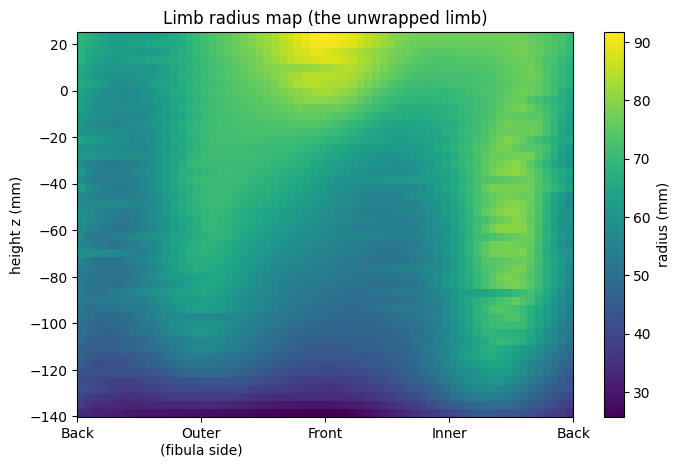

In [ ]:
SIDE_TICKS = ([-180, -90, 0, 90, 180], ['Back', 'Outer\n(fibula side)', 'Front', 'Inner', 'Back'])

def show_grid(G, f, title, label, cmap='viridis', ax=None, vmin=None, vmax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(G, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=[-180, 180, f['Z'][-1], f['Z'][0]])
    ax.set_xticks(*SIDE_TICKS)
    ax.set_ylabel('height z (mm)')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label=label)
    return ax

show_grid(R_ref, f, 'Limb radius map (the unwrapped limb)', 'radius (mm)')
plt.show()

### Grid matching to limb check


In [ ]:
def grid_error(R, f):
    mesh = trimesh.Trimesh(f['skin'][REF], D['skin_faces'], process=False)
    pts = to_xyz(R, f['Z'], f['axis']).reshape(-1, 3)
    _, dist, _ = trimesh.proximity.closest_point(mesh, pts[::5])  # save time
    return dist

err = grid_error(R_ref, f)
print(f'Grid vs real skin (mm): median {np.median(err):.2f}, 95th percentile {np.percentile(err, 95):.2f}, max {err.max():.2f}')

Grid vs real skin (mm): median 0.41, 95th percentile 2.97, max 7.05


## Visualize tissue thickness on radius map


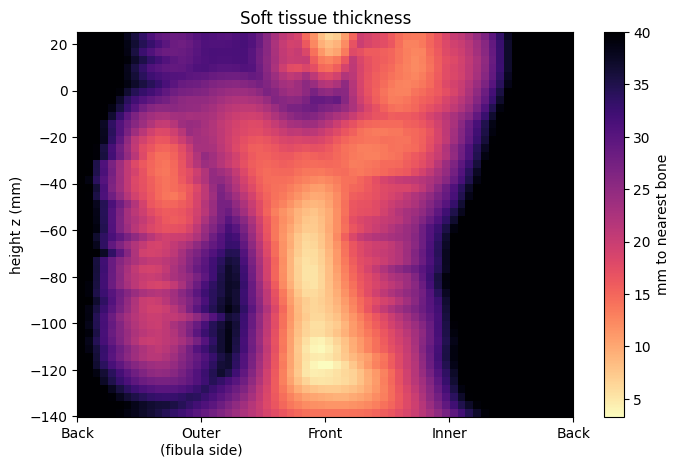

Thinnest: 3.3 mm | share of grid under 10 mm: 5.8%


In [ ]:
def thickness_map(R, f):
    pts = to_xyz(R, f['Z'], f['axis']).reshape(-1, 3)
    dist, _ = cKDTree(f['bone']).query(pts)
    return dist.reshape(R.shape)

T_ref = thickness_map(R_ref, f)
show_grid(T_ref, f, 'Soft tissue thickness', 'mm to nearest bone', cmap='magma_r', vmax=40)
plt.show()
print(f'Thinnest: {T_ref.min():.1f} mm | share of grid under 10 mm: {(T_ref < 10).mean():.1%}')

## Define landmarks and danger zones


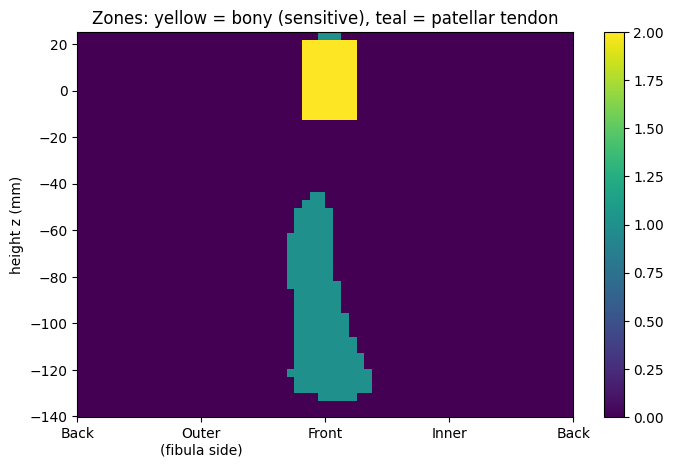

{'z_joint': np.float64(4.6), 'z_pat': np.float64(25.2), 'z_tt': np.float64(-15.6), 'th_tt': 8, 'z_fh': np.float64(-23.3), 'th_fh': -114, 'z_de': np.float64(-121.9), 'th_de': 13}


In [ ]:
BONY_MM = 10.0
MIN_BONY_FRAC = 0.05

def angle_of(pt, axis):
    return float(np.arctan2(pt[0] - axis[0], -(pt[1] - axis[1])))

def landmarks(f):
    b, ax = f['bone'], f['axis']
    tib, fib = b[TIBIA], b[FIBULA]
    z_joint = tib[:, 2].max()
    upper = tib[(tib[:, 2] > z_joint - 40) & (tib[:, 2] < z_joint - 10)]
    tt = upper[np.argmin(upper[:, 1])]  # tubercle
    fh = fib[np.argmax(fib[:, 2])]  # top of fibula
    de = tib[tib[:, 2] < tib[:, 2].min() + 15].mean(0)  # bottom end of tibia
    return dict(z_joint=z_joint, z_pat=b[PATELLA][:, 2].min(),
                z_tt=tt[2], th_tt=angle_of(tt, ax),
                z_fh=fh[2], th_fh=angle_of(fh, ax),
                z_de=de[2], th_de=angle_of(de, ax))

def zone_masks(f, T, L):
    Z = f['Z']
    front = np.abs(THETA) < np.radians(20)
    pt = front[None, :] & ((Z < L['z_pat'] - 3) & (Z > L['z_tt'] + 5))[:, None]
    bony = (T < BONY_MM) & ~pt
    if bony.sum() < MIN_BONY_FRAC * T.size:  # too few thin spots
        cutoff = np.quantile(T[~pt], MIN_BONY_FRAC)
        bony = (T <= cutoff) & ~pt
    return bony, pt

L = landmarks(f)
bony, pt = zone_masks(f, T_ref, L)
zones = bony * 1.0 + pt * 2.0
show_grid(zones, f, 'Zones: yellow = bony (sensitive), teal = patellar tendon', '', cmap='viridis')
plt.show()
print({k: (round(np.degrees(v)) if k.startswith('th') else round(v, 1)) for k, v in L.items()})

## Assign physics value from literature

- `E_TISSUE`: residual limb soft tissue stiffness (kPa)
- `MU`: friction coefficient between skin or liner and socket
- `LOAD_N`: load standing on two legs

In [ ]:
E_TISSUE = 40.0    # kPa   Silver-Thorn B., &  Childress D. S. (1997)
MU       = 0.75    # -     Xie et al. (2021)
LOAD_N   = 400.0   # N     Steer et al. (2020)
T_MIN    = 2.0     # mm    fixes shape model quirk

### Building one patient at one volume version (case)


In [ ]:
def make_case(p, v):
    f = frame(p)
    R_ref = radius_map(f['skin'][REF], f['axis'], f['Z'])
    z_ext = np.linspace(f['z_bot'] - EXT_DOWN, f['z_top'] + EXT_UP, N_EXT)
    R_ext = np.nan_to_num(radius_map(f['skin'][v], f['axis'], z_ext), nan=0.0)  # no limb below the tip
    R_v = radius_map(f['skin'][v], f['axis'], f['Z'])
    T = thickness_map(R_v, f)
    return dict(f=f, Z=f['Z'], R_ref=R_ref, R_ext=R_ext, z_ext0=z_ext[0],
                dz_ext=z_ext[1] - z_ext[0], T=T, v=v)

### Build simulator


In [ ]:
def limb_at(case, ds):
    zq = case['Z'] + ds
    idx = np.clip((zq - case['z_ext0']) / case['dz_ext'], 0, N_EXT - 1.001)
    i0 = np.floor(idx).astype(int)
    fr = (idx - i0)[:, None]
    return case['R_ext'][i0] * (1 - fr) + case['R_ext'][i0 + 1] * fr

def simulate(case, offset, load=LOAD_N, E=E_TISSUE, mu=MU):
    S = case['R_ref'] + offset  # socket radius
    Z = case['Z']
    k = E / np.maximum(case['T'], T_MIN)
    dSdz = np.gradient(S, Z, axis=0)
    dth, dz = 2 * np.pi / W, abs(Z[1] - Z[0])

    def force(ds):
        P = k * np.clip(limb_at(case, ds) - S, 0, None)  # pressure (kPa)
        lift = S * (dSdz + mu * np.sqrt(1 + dSdz ** 2))  # taper + friction
        return (P * lift).sum() * dth * dz * 1e-3, P     # newtons

    lo, hi = -30.0, 80.0
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        if force(mid)[0] < load:
            lo = mid
        else:
            hi = mid
    ds = 0.5 * (lo + hi)
    F, P = force(ds)
    return dict(P=P, sink=ds, F=F, ok=abs(F - load) < 1.0)

## Test plain socket without offsets


Balanced: True | sank 10.7 mm | upward force 400 N
Peak pressure, bony zone: 62 kPa | peak anywhere: 62 kPa
Share of the socket touching the limb: 87%


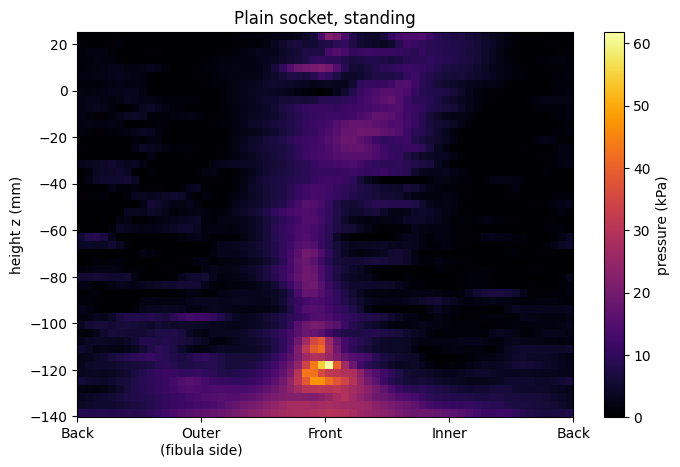

In [ ]:
case = make_case(0, REF)
plain = simulate(case, np.zeros((H, W)))
P = plain['P']
print(f"Balanced: {plain['ok']} | sank {plain['sink']:.1f} mm | upward force {plain['F']:.0f} N")
print(f'Peak pressure, bony zone: {P[bony].max():.0f} kPa | peak anywhere: {P.max():.0f} kPa')
print(f'Share of the socket touching the limb: {(P > 0).mean():.0%}')
show_grid(P, f, 'Plain socket, standing', 'pressure (kPa)', cmap='inferno')
plt.show()

### 3D Visualization of pressure map

In [ ]:
def show_socket_3d(case, offset, P, title):
    S = case['R_ref'] + offset
    xyz = to_xyz(S, case['Z'], case['f']['axis'])
    xyz = np.concatenate([xyz, xyz[:, :1]], axis=1)          # close the seam
    Pc = np.concatenate([P, P[:, :1]], axis=1)
    bv, fb = case['f']['bone'], D['bone_faces']
    fig = go.Figure([
        go.Surface(x=xyz[..., 0], y=xyz[..., 1], z=xyz[..., 2], surfacecolor=Pc,
                   colorscale='Inferno', colorbar=dict(title='kPa'), opacity=0.9),
        go.Mesh3d(x=bv[:, 0], y=bv[:, 1], z=bv[:, 2], i=fb[:, 0], j=fb[:, 1], k=fb[:, 2],
                  color='ivory', opacity=0.6, name='bone'),
    ])
    fig.update_layout(title=title, scene=dict(aspectmode='data'), height=650)
    fig.show()

show_socket_3d(case, np.zeros((H, W)), P, 'Plain socket pressure')

## Control knobs to design sockets


All knobs = 1 mm gives offsets from 1.0 to 1.0


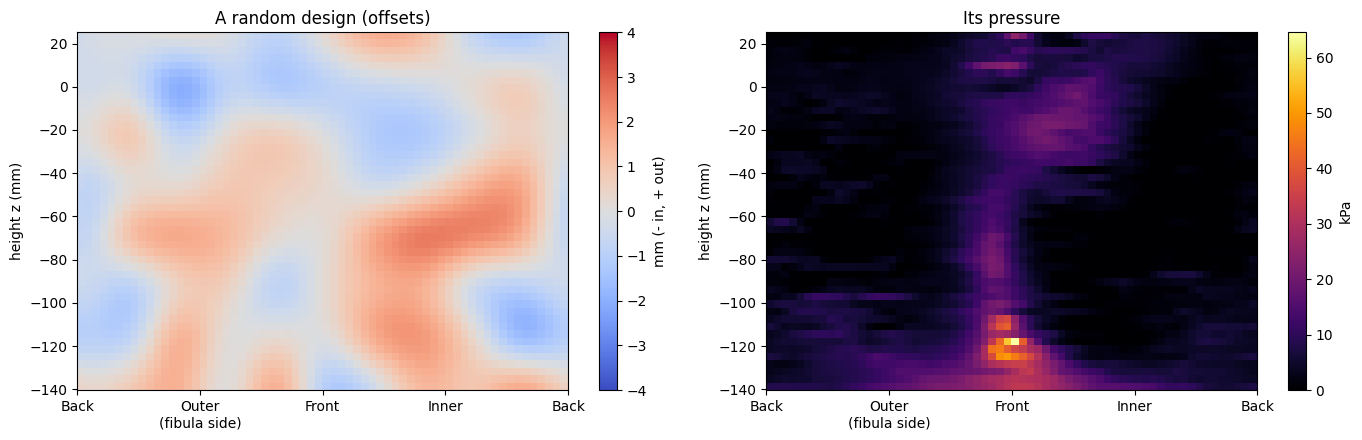

In [ ]:
NK_Z, NK_TH = 8, 10

def basis(n_out, n_knobs, wrap):
    x = np.linspace(0, 1, n_out, endpoint=not wrap)
    c = np.linspace(0, 1, n_knobs, endpoint=not wrap)
    dx = x[:, None] - c[None, :]
    if wrap:
        dx = (dx + 0.5) % 1.0 - 0.5  # wrap-around distance
    sigma = 0.6 / (n_knobs if wrap else n_knobs - 1)
    B = np.exp(-0.5 * (dx / sigma) ** 2)
    return B / B.sum(axis=1, keepdims=True)

BZ, BTH = basis(H, NK_Z, wrap=False), basis(W, NK_TH, wrap=True)

def knobs_to_offset(knobs):
    return BZ @ knobs @ BTH.T

print('All knobs = 1 mm gives offsets from', knobs_to_offset(np.ones((NK_Z, NK_TH))).min().round(4),
      'to', knobs_to_offset(np.ones((NK_Z, NK_TH))).max().round(4))

rng = np.random.default_rng(0)
demo = knobs_to_offset(rng.normal(0, 2, (NK_Z, NK_TH)))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
show_grid(demo, f, 'A random design (offsets)', 'mm (- in, + out)', cmap='coolwarm', ax=axs[0], vmin=-4, vmax=4)
show_grid(simulate(case, demo)['P'], f, 'Its pressure', 'kPa', cmap='inferno', ax=axs[1])
plt.tight_layout(); plt.show()

## PTB socket design


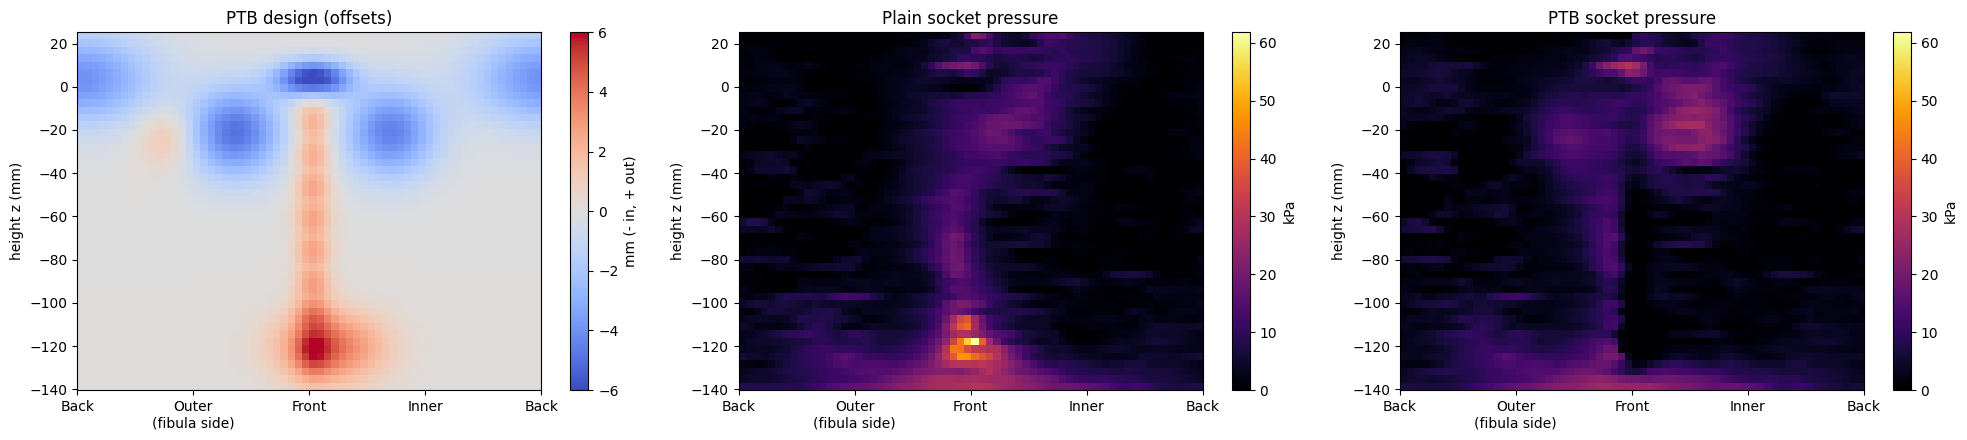

plain  bony peak   61.8 kPa | tendon avg   8.7 kPa | sink 10.7 mm | contact 87%
PTB    bony peak   20.0 kPa | tendon avg  12.2 kPa | sink 10.2 mm | contact 87%


In [ ]:
def bump(Z, z0, th0, size_z, size_deg):
    dth = np.angle(np.exp(1j * (THETA - th0)))          # wrap-around angle difference
    return np.exp(-0.5 * ((Z[:, None] - z0) / size_z) ** 2
                  - 0.5 * (dth[None, :] / np.radians(size_deg)) ** 2)

def ptb_template(f, L):
    Z = f['Z']
    z_pt = 0.5 * (L['z_pat'] + L['z_tt'])
    off  = -6.7 * bump(Z, z_pt, 0, 6, 20)                                # PT bar [(Dickinson et al. (2021)]
    off += -4.5 * bump(Z, L['z_joint'] - 25, np.radians(60), 15, 25)     # medial paratibial [Dickinson et al. (2021)]
    off += -4.9 * bump(Z, L['z_joint'] - 25, np.radians(-60), 15, 25)    # lateral paratibial [Dickinson et al. (2021)]
    off += -4 * bump(Z, z_pt, np.pi, 15, 40)                             # back of knee (assumed)
    off += +1.6 * bump(Z, L['z_fh'], L['th_fh'], 10, 15)                 # fibular head [Dickinson et al. (2021)]
    off += +4.1 * bump(Z, L['z_de'], L['th_de'], 12, 30)                 # distal end [Dickinson et al. (2021)]
    crest = np.zeros_like(off)
    for zc in np.linspace(L['z_tt'], L['z_de'], 8):
        crest = np.maximum(crest, bump(Z, zc, 0, 10, 10))
    off += +2.7 * crest                                                  # tibial crest [Dickinson et al. (2024)]
    return off

ptb = ptb_template(f, L)
res_ptb = simulate(case, ptb)

fig, axs = plt.subplots(1, 3, figsize=(20, 4.5))
show_grid(ptb, f, 'PTB design (offsets)', 'mm (- in, + out)', cmap='coolwarm', ax=axs[0], vmin=-6, vmax=6)
vmax = max(P.max(), res_ptb['P'].max())
show_grid(P, f, 'Plain socket pressure', 'kPa', cmap='inferno', ax=axs[1], vmax=vmax)
show_grid(res_ptb['P'], f, 'PTB socket pressure', 'kPa', cmap='inferno', ax=axs[2], vmax=vmax)
plt.tight_layout(); plt.show()

for name, r in [('plain', plain), ('PTB', res_ptb)]:
    print(f"{name:5s}  bony peak {r['P'][bony].max():6.1f} kPa | tendon avg {r['P'][pt].mean():5.1f} kPa | "
          f"sink {r['sink']:4.1f} mm | contact {(r['P'] > 0).mean():.0%}")

## Test both designs at every volume version


In [ ]:
def day_test(p, offsets_by_name):
    f = frame(p)
    L = landmarks(f)
    cases = [make_case(p, v) for v in range(len(VOLUME_CHANGES))]
    bony_ref, _ = zone_masks(f, cases[REF]['T'], L)
    table = {}
    for name, off in offsets_by_name.items():
        table[name] = [simulate(c, off)['P'][bony_ref].max() for c in cases]
    return table

for p in range(3):
    f_p = frame(p)
    t = day_test(p, {'plain': np.zeros((H, W)), 'PTB': ptb_template(f_p, landmarks(f_p))})
    print(f'\nPatient {p}  (bony peak, kPa)')
    print('  volume: ' + '  '.join(f'{v:+.2%}' for v in VOLUME_CHANGES) + '   WORST')
    for name, row in t.items():
        print(f'  {name:6s}  ' + '  '.join(f'{x:6.1f}' for x in row) + f'   {max(row):6.1f}')


Patient 0  (bony peak, kPa)
  volume: -1.50%  -0.75%  +0.00%  +1.00%  +2.00%   WORST
  plain     67.5    64.7    61.8    56.8    64.6     67.5
  PTB       26.9    20.0    20.0    19.7    17.3     26.9

Patient 1  (bony peak, kPa)
  volume: -1.50%  -0.75%  +0.00%  +1.00%  +2.00%   WORST
  plain     66.6    65.9    64.9    58.0    54.8     66.6
  PTB       60.8    51.8    49.4    47.0    47.6     60.8

Patient 2  (bony peak, kPa)
  volume: -1.50%  -0.75%  +0.00%  +1.00%  +2.00%   WORST
  plain     84.8    85.7    85.9    85.9    82.4     85.9
  PTB       73.4    71.8    71.5    71.6    67.0     73.4


## Sanity check


In [ ]:
checks = []
for p in range(min(N_PATIENTS, 5)):
    for v in range(len(VOLUME_CHANGES)):
        r = simulate(make_case(p, v), np.zeros((H, W)))
        checks.append((r['ok'], r['sink'], r['P'].max()))
ok, sink, peak = map(np.array, zip(*checks))
print(f'All balanced: {ok.all()} | sink {sink.min():.1f} to {sink.max():.1f} mm | peaks {peak.min():.0f} to {peak.max():.0f} kPa')

All balanced: True | sink 3.5 to 30.7 mm | peaks 55 to 167 kPa


In [ ]:
print(f'E = {E_TISSUE} kPa, MU = {MU}\n')
print('patient  volume    sink(mm)  peak(kPa)  peak at height(mm)  angle(deg)  tissue there(mm)')
for p in range(min(N_PATIENTS, 5)):
    for v in range(len(VOLUME_CHANGES)):
        c = make_case(p, v)
        r = simulate(c, np.zeros((H, W)))
        i, j = np.unravel_index(r['P'].argmax(), r['P'].shape)
        flag = '  <-- check' if r['sink'] > 15 else ''
        print(f'{p:7d}  {VOLUME_CHANGES[v]:+.2%}  {r["sink"]:8.1f}  {r["P"].max():9.0f}'
              f'  {c["Z"][i]:18.0f}  {np.degrees(THETA[j]):10.0f}  {c["T"][i, j]:16.1f}{flag}')

E = 40.0 kPa, MU = 0.75

patient  volume    sink(mm)  peak(kPa)  peak at height(mm)  angle(deg)  tissue there(mm)
      0  -1.50%      11.5         67                -119           0               3.3
      0  -0.75%      11.1         65                -119           0               3.3
      0  +0.00%      10.7         62                -119           0               3.3
      0  +1.00%      10.2         57                -119           0               3.3
      0  +2.00%       9.3         65                -119           0               3.3
      1  -1.50%      17.6         67                 -72         -22               1.4  <-- check
      1  -0.75%      17.3         66                 -72         -22               1.5  <-- check
      1  +0.00%      16.7         65                 -72         -22               1.5  <-- check
      1  +1.00%      15.5         58                -164         -17               3.5  <-- check
      1  +2.00%      14.9         55                -164   

In [ ]:
def show_patient(p, v=None):
    v = REF if v is None else v
    skin, bone = D['skin'][p, v], D['bone'][p]
    sf, bf = D['skin_faces'], D['bone_faces']
    fig = go.Figure([
        go.Mesh3d(x=skin[:, 0], y=skin[:, 1], z=skin[:, 2],
                  i=sf[:, 0], j=sf[:, 1], k=sf[:, 2], color='tan', opacity=0.35, name='skin'),
        go.Mesh3d(x=bone[:, 0], y=bone[:, 1], z=bone[:, 2],
                  i=bf[:, 0], j=bf[:, 1], k=bf[:, 2], color='ivory', name='bone'),
    ])
    fig.update_layout(title=f'Patient {p}, volume {VOLUME_CHANGES[v]:+.2%}',
                      scene=dict(aspectmode='data'), height=600)
    fig.show()

show_patient(0)

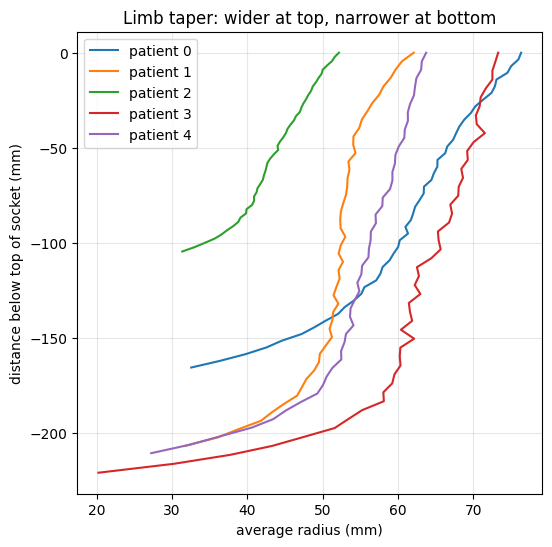

In [ ]:
def taper_profile(patients):
    plt.figure(figsize=(6, 6))
    for p in patients:
        f_p = frame(p)
        R = radius_map(f_p['skin'][REF], f_p['axis'], f_p['Z'])
        plt.plot(R.mean(axis=1), f_p['Z'] - f_p['Z'][0], label=f'patient {p}')
    plt.xlabel('average radius (mm)')
    plt.ylabel('distance below top of socket (mm)')
    plt.title('Limb taper: wider at top, narrower at bottom')
    plt.legend(); plt.grid(alpha=0.3); plt.show()

taper_profile([0, 1, 2, 3, 4])

In [ ]:
rows = []
for p in range(min(N_PATIENTS, 5)):
    f_p = frame(p)
    for v in range(len(VOLUME_CHANGES)):
        r = simulate(make_case(p, v), np.zeros((H, W)))
        rows.append((p, VOLUME_CHANGES[v], r['sink'], f_p['z_top'] - f_p['z_bot']))

rows.sort(key=lambda x: -x[2])          # biggest sink first
print('patient  volume    sink(mm)  socket length(mm)')
for p, vol, sink, length in rows[:10]:
    print(f'{p:7d}  {vol:+.2%}  {sink:8.1f}  {length:17.0f}')

patient  volume    sink(mm)  socket length(mm)
      2  -1.50%      30.7                104
      2  -0.75%      30.1                104
      2  +0.00%      29.9                104
      2  +1.00%      29.5                104
      2  +2.00%      28.6                104
      1  -1.50%      17.6                207
      1  -0.75%      17.3                207
      1  +0.00%      16.7                207
      4  -1.50%      15.7                211
      1  +1.00%      15.5                207


In [ ]:
for p in [0, 1, 2, 4]:
    f_p = frame(p)
    ptb_p = ptb_template(f_p, landmarks(f_p))
    plain_s = simulate(make_case(p, REF), np.zeros((H, W)))['sink']
    ptb_s = simulate(make_case(p, REF), ptb_p)['sink']
    print(f'patient {p}: plain sinks {plain_s:5.1f} mm | PTB sinks {ptb_s:5.1f} mm')

patient 0: plain sinks  10.7 mm | PTB sinks  10.2 mm
patient 1: plain sinks  16.7 mm | PTB sinks  14.9 mm
patient 2: plain sinks  29.9 mm | PTB sinks  27.7 mm
patient 4: plain sinks  14.4 mm | PTB sinks  13.1 mm


## Run simulator for every patient and save results


In [ ]:
NV = len(VOLUME_CHANGES)
out = {k: [] for k in ['R_ref', 'R_ext', 'z_ext0', 'dz_ext', 'T', 'Z', 'bony', 'pt', 'ptb', 'unbalanced']}
for p in range(N_PATIENTS):
    cases = [make_case(p, v) for v in range(NV)]
    f_p, L_p = cases[0]['f'], landmarks(cases[0]['f'])
    bony_p, pt_p = zone_masks(f_p, cases[REF]['T'], L_p)
    ptb_p = ptb_template(f_p, L_p)
    out['R_ref'].append(cases[REF]['R_ref'])
    out['R_ext'].append(np.stack([c['R_ext'] for c in cases]))
    out['z_ext0'].append([c['z_ext0'] for c in cases])
    out['dz_ext'].append([c['dz_ext'] for c in cases])
    out['T'].append(np.stack([c['T'] for c in cases]))
    out['Z'].append(f_p['Z'])
    out['bony'].append(bony_p); out['pt'].append(pt_p); out['ptb'].append(ptb_p)
    out['unbalanced'].append(sum(not simulate(c, ptb_p)['ok'] for c in cases))
    if (p + 1) % 10 == 0:
        print(f'{p + 1}/{N_PATIENTS} patients done')

grid_path = f'{OUT_DIR}/socket_grids_v1.npz'
np.savez_compressed(grid_path,
    **{k: np.array(v, dtype=np.float32) for k, v in out.items() if k not in ('bony', 'pt', 'unbalanced')},
    bony=np.array(out['bony']), pt=np.array(out['pt']),
    groups=D['groups'], volume_changes=np.array(VOLUME_CHANGES), ref_index=REF,
    theta=THETA, BZ=BZ, BTH=BTH,
    settings=np.array([E_TISSUE, MU, LOAD_N, T_MIN, BONY_MM]))
print('Saved', grid_path)
print('Simulations that failed to balance:', int(sum(out['unbalanced'])))

10/200 patients done
20/200 patients done
30/200 patients done
40/200 patients done
50/200 patients done
60/200 patients done
70/200 patients done
80/200 patients done
90/200 patients done
100/200 patients done
110/200 patients done
120/200 patients done
130/200 patients done
140/200 patients done
150/200 patients done
160/200 patients done
170/200 patients done
180/200 patients done
190/200 patients done
200/200 patients done
Saved /content/drive/MyDrive/all-day-socket/data/socket_grids_v1.npz
Simulations that failed to balance: 0
